# Predicting Racing Lap Times with Linear Regression

This is a small beginner-friendly machine learning project. The goal is to estimate a racing lap's time (in seconds) from a few track and race-condition features.

I kept the workflow straightforward on purpose: inspect the data, look at feature correlations, split the data, train a Linear Regression model, and evaluate its predictions.

**Dataset note:** place `racing_lap_times_numeric.csv` in the same folder as this notebook before running it.

## 1. Import the libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Load the dataset

In [15]:
# Keep the CSV next to this notebook so the path works when you run the project.
df = pd.read_csv("racing_lap_times_numeric.csv")

# A quick look at a few rows helps us understand what each record represents.
df.head()

,avg_speed_kmh,tyre_wear_pct,track_temp_c,wind_speed_mps,pit_stop_flag,lap_time_sec
0,174.577,27.026,31.524,2.270,0,75.822
1,172.009,32.162,24.800,1.936,1,88.448
2,185.208,27.187,33.752,3.037,1,87.322
3,183.022,42.911,34.703,2.728,1,86.379
4,163.143,36.438,20.245,1.583,1,86.942


## 3. Get familiar with the data

In [3]:
print(f"Dataset shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.info()

Dataset shape: 2000 rows, 6 columns
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   avg_speed_kmh   2000 non-null   float64
 1   tyre_wear_pct   2000 non-null   float64
 2   track_temp_c    2000 non-null   float64
 3   wind_speed_mps  2000 non-null   float64
 4   pit_stop_flag   2000 non-null   int64  
 5   lap_time_sec    2000 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 93.9 KB


In [4]:
# Missing values can affect training, so check them before building a model.
print("Missing values in each column:")
display(df.isna().sum())

# Summary statistics give us a first sense of each column's scale and range.
display(df.describe())

Missing values in each column:


avg_speed_kmh     0
tyre_wear_pct     0
track_temp_c      0
wind_speed_mps    0
pit_stop_flag     0
lap_time_sec      0
dtype: int64

,avg_speed_kmh,tyre_wear_pct,track_temp_c,wind_speed_mps,pit_stop_flag,lap_time_sec
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,180.193454,25.117428,29.724337,2.032772,0.491000,80.210206
std,11.959602,8.052854,5.010266,1.114196,0.500044,6.456283
min,143.235000,0.000000,11.758000,0.000000,0.000000,63.928000
25%,171.954500,19.654000,26.400250,1.226500,0.000000,74.269250
50%,180.164000,25.199000,29.888000,1.927500,0.000000,79.281500
75%,188.193750,30.241750,32.997250,2.797000,1.000000,86.278000
max,217.062000,52.632000,45.894000,5.953000,1.000000,94.282000


## 4. Explore relationships between features

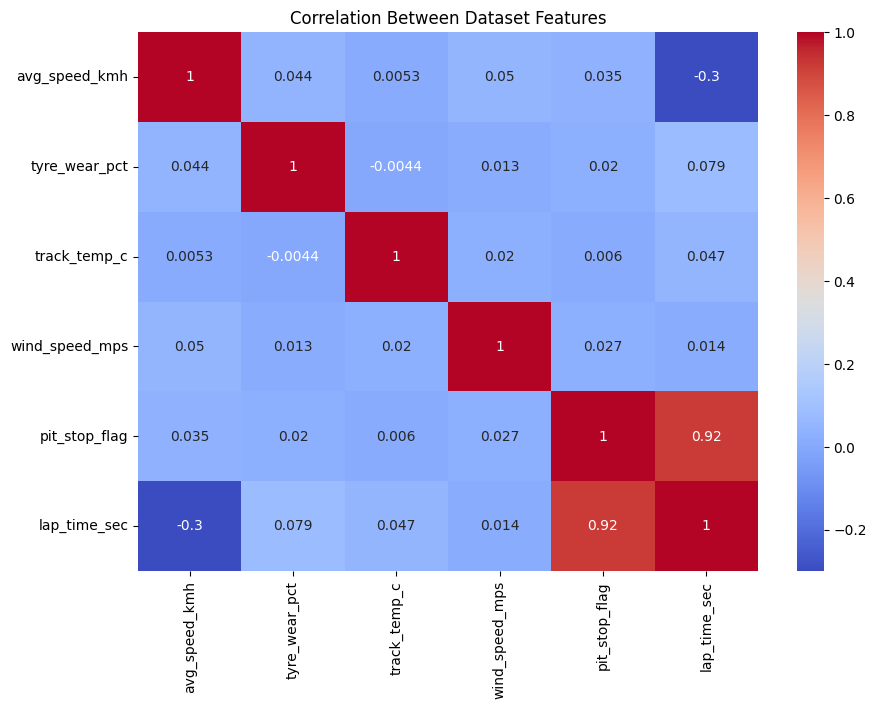

In [14]:
# Correlations can reveal which numeric columns move together.
# They are useful for exploration, but correlation alone does not prove causation.
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm", annot=True)
plt.title("Correlation Between Dataset Features")
plt.show()

## 5. Define the features and target

The target is `lap_time_sec`, which is the value we want the model to predict. The remaining columns are used as input features.

In [ ]:
target_column = "lap_time_sec"

if target_column not in df.columns:
    raise ValueError(f"Expected target column '{target_column}' was not found in the dataset.")

# This basic project uses complete rows only; check the missing-value output above
# if you need to decide on a more deliberate imputation strategy.
df_model = df.dropna().copy()
X = df_model.drop(columns=[target_column])
y = df_model[target_column]

print("Feature columns:", list(X.columns))
print("Target column:", target_column)


Feature columns: ['avg_speed_kmh', 'tyre_wear_pct', 'track_temp_c', 'wind_speed_mps', 'pit_stop_flag']
Target column: lap_time_sec
Rows available for modeling: 2000


## 6. Split the data

In [ ]:
# Keep the test set separate so we can evaluate the model on data it did not train on.
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

print(f"Training rows: {len(X_train)}")
print(f"Testing rows: {len(X_test)}")

Training rows: 1600
Testing rows: 400


## 7. Train a Linear Regression model

In [8]:
# Linear Regression is a useful baseline because it is simple and easy to interpret.
model = LinearRegression()
model.fit(X_train, y_train)

# Generate predictions for the held-out test set.
y_pred = model.predict(X_test)

## 8. Evaluate the model

For a regression task, **R² is not classification accuracy**. It describes how much of the variation in the target is explained by the model on this test set. MAE and RMSE express prediction error in seconds; lower values are generally better.

In [9]:
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.3f} seconds")
print(f"RMSE: {rmse:.3f} seconds")
print(f"R²:   {r2:.3f}")

MAE:  0.967 seconds
RMSE: 1.193 seconds
R²:   0.965


## 9. Compare actual and predicted lap times

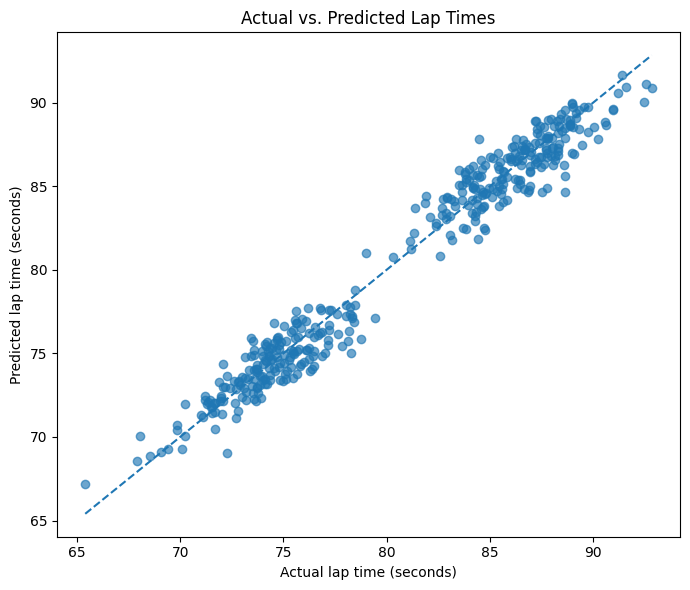

In [10]:
# Points close to the diagonal are predictions that are close to the actual values.
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.65)
lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())
plt.plot([lower, upper], [lower, upper], linestyle="--")
plt.xlabel("Actual lap time (seconds)")
plt.ylabel("Predicted lap time (seconds)")
plt.title("Actual vs. Predicted Lap Times")
plt.tight_layout()
plt.show()

## 10. Look at prediction errors

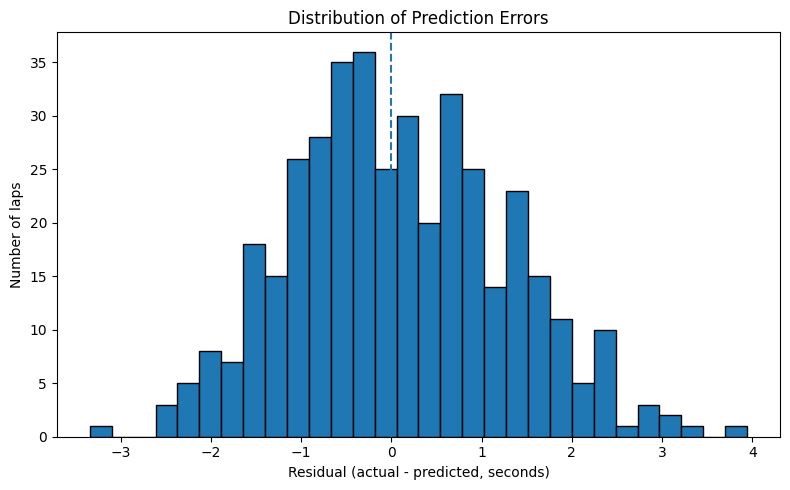

In [11]:
# Residuals show how far each prediction was from the actual lap time.
# Here, a positive residual means the actual time was higher than the prediction.
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=30, edgecolor="black")
plt.axvline(0, linestyle="--")
plt.xlabel("Residual (actual - predicted, seconds)")
plt.ylabel("Number of laps")
plt.title("Distribution of Prediction Errors")
plt.tight_layout()
plt.show()

## 11. Try a few predictions

This table makes it easier to inspect individual predictions rather than relying on one score alone.

In [16]:
comparison = pd.DataFrame({
    "actual_lap_time_sec": y_test,
    "predicted_lap_time_sec": y_pred
})
comparison["absolute_error_sec"] = (comparison["actual_lap_time_sec"] - comparison["predicted_lap_time_sec"]).abs()
df.head(10)

,avg_speed_kmh,tyre_wear_pct,track_temp_c,wind_speed_mps,pit_stop_flag,lap_time_sec
0,174.577,27.026,31.524,2.270,0,75.822
1,172.009,32.162,24.800,1.936,1,88.448
2,185.208,27.187,33.752,3.037,1,87.322
3,183.022,42.911,34.703,2.728,1,86.379
4,163.143,36.438,20.245,1.583,1,86.942
5,193.472,22.540,23.489,2.654,0,70.306
6,178.870,22.456,30.639,0.796,0,73.166
7,166.669,28.758,28.419,0.294,0,77.830
8,194.265,18.296,29.916,1.774,1,80.166
9,187.508,34.330,25.735,2.493,0,72.857


## What I learned

- How to inspect a dataset before training a model.
- How to separate input features from the value being predicted.
- How to split data into training and test sets.
- How to train a Linear Regression baseline and evaluate it with R², MAE, and RMSE.
- How to visualize predictions and their errors.

## Possible next steps

- Compare Linear Regression with a tree-based model such as Random Forest.
- Check whether any input feature would be unavailable at the moment a real prediction is made.
- If the rows represent laps in chronological or race order, consider a time-aware split instead of a random split.
- Document where the dataset came from and what each column means.

**Important:** a strong test score does not automatically mean the model will generalize to every race. The result depends on how the dataset was collected and whether the features would genuinely be available when making a prediction.